# DeepTuneIO Analyzer — Contention Analysis (v6)

Visualización de coincidencias DXT con títulos descriptivos y paletas seleccionables. Las coincidencias no demuestran por sí mismas degradación.


In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image

# Localiza el módulo aunque Jupyter se abra desde la raíz del proyecto.
CANDIDATES = [
    Path.cwd(),
    Path.cwd() / "10_Visualization" / "Contention_Analysis",
    Path.cwd() / "Contention_Analysis",
]
ROOT = next((p.resolve() for p in CANDIDATES if (p / "Module" / "contention_pipeline.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError(
        "No encuentro Module/contention_pipeline.py. Abre el notebook desde "
        "10_Visualization/Contention_Analysis o desde la raíz DeepTuneIO."
    )
ACCESS_PATTERN_MODULE = ROOT.parent / "Access_Pattern" / "Module"
if not (ACCESS_PATTERN_MODULE / "Access_Pattern_Visualization" / "processor.py").is_file():
    raise FileNotFoundError(
        f"Falta Access_Pattern: {ACCESS_PATTERN_MODULE}. "
        "Instala ambas carpetas al mismo nivel dentro de 10_Visualization."
    )
sys.path.insert(0, str(ACCESS_PATTERN_MODULE))
sys.path.insert(0, str(ROOT / "Module"))
from contention_pipeline import run_contention
print("Contention_Analysis:", ROOT)
print("Detector Access_Pattern:", ACCESS_PATTERN_MODULE)


Contention_Analysis: F:\NoteBooks\CORA_DR_UAB\Tesis\Scripts\DeepTuneIO\10_Visualization\Contention_Analysis
Detector Access_Pattern: F:\NoteBooks\CORA_DR_UAB\Tesis\Scripts\DeepTuneIO\10_Visualization\Access_Pattern\Module


## Configuración
Selecciona una campaña y un JobID con eventos DXT. El módulo localiza los CSV de eventos automáticamente en `CAMPAIGN_ROOT/results`.


In [2]:
CAMPAIGN_ROOT = Path(r"D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1")
APPLICATION = "DeepGalaxy"
DATASET_GROUP = "DG_bw512_f3c5x64"
SCENARIO = "nfs_SnGPU_e1"
FILE_FORMAT = "hdf5"
JOBID = 5333197
OPERATION = "read"       # read, write, all
CASE = "AB"              # AB, A_exact, B_partial, C_shared_resource
PROCESS = None           # None = todos los procesos
FILE = None              # None = un mapa por archivo
TIME_BINS = 50
OFFSET_BINS = 40
RESOURCE_MODE = "auto"   # auto, ost, nfs, none
OUTPUT_DIR = None        # Por defecto, en results/Figures/Contention_Analysis/job_<JobID>

# Paleta aplicable a ambos mapas. Opciones: Blues, viridis, cividis, YlOrRd, magma, plasma, PuBuGn, turbo
PALETTE = "viridis"
LOG_SCALE = True  # False = escala lineal


Eventos DXT: 672990
Pares detectados: 200000
Casos: {'C_shared_resource': 124518, 'A_exact': 75312, 'B_partial': 170}
Truncado: True
Fuentes:
 - D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1\results\Access_Pattern_DXT\Analysis\13_DG_N16p64e1_EfficientNetB4_outputbw512hdf5_ds36nc14_M0_nfs_5333197_FT3RESDT_dxt_analysis.csv
Resultados: D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1\results\Figures\Contention_Analysis\job_5333197


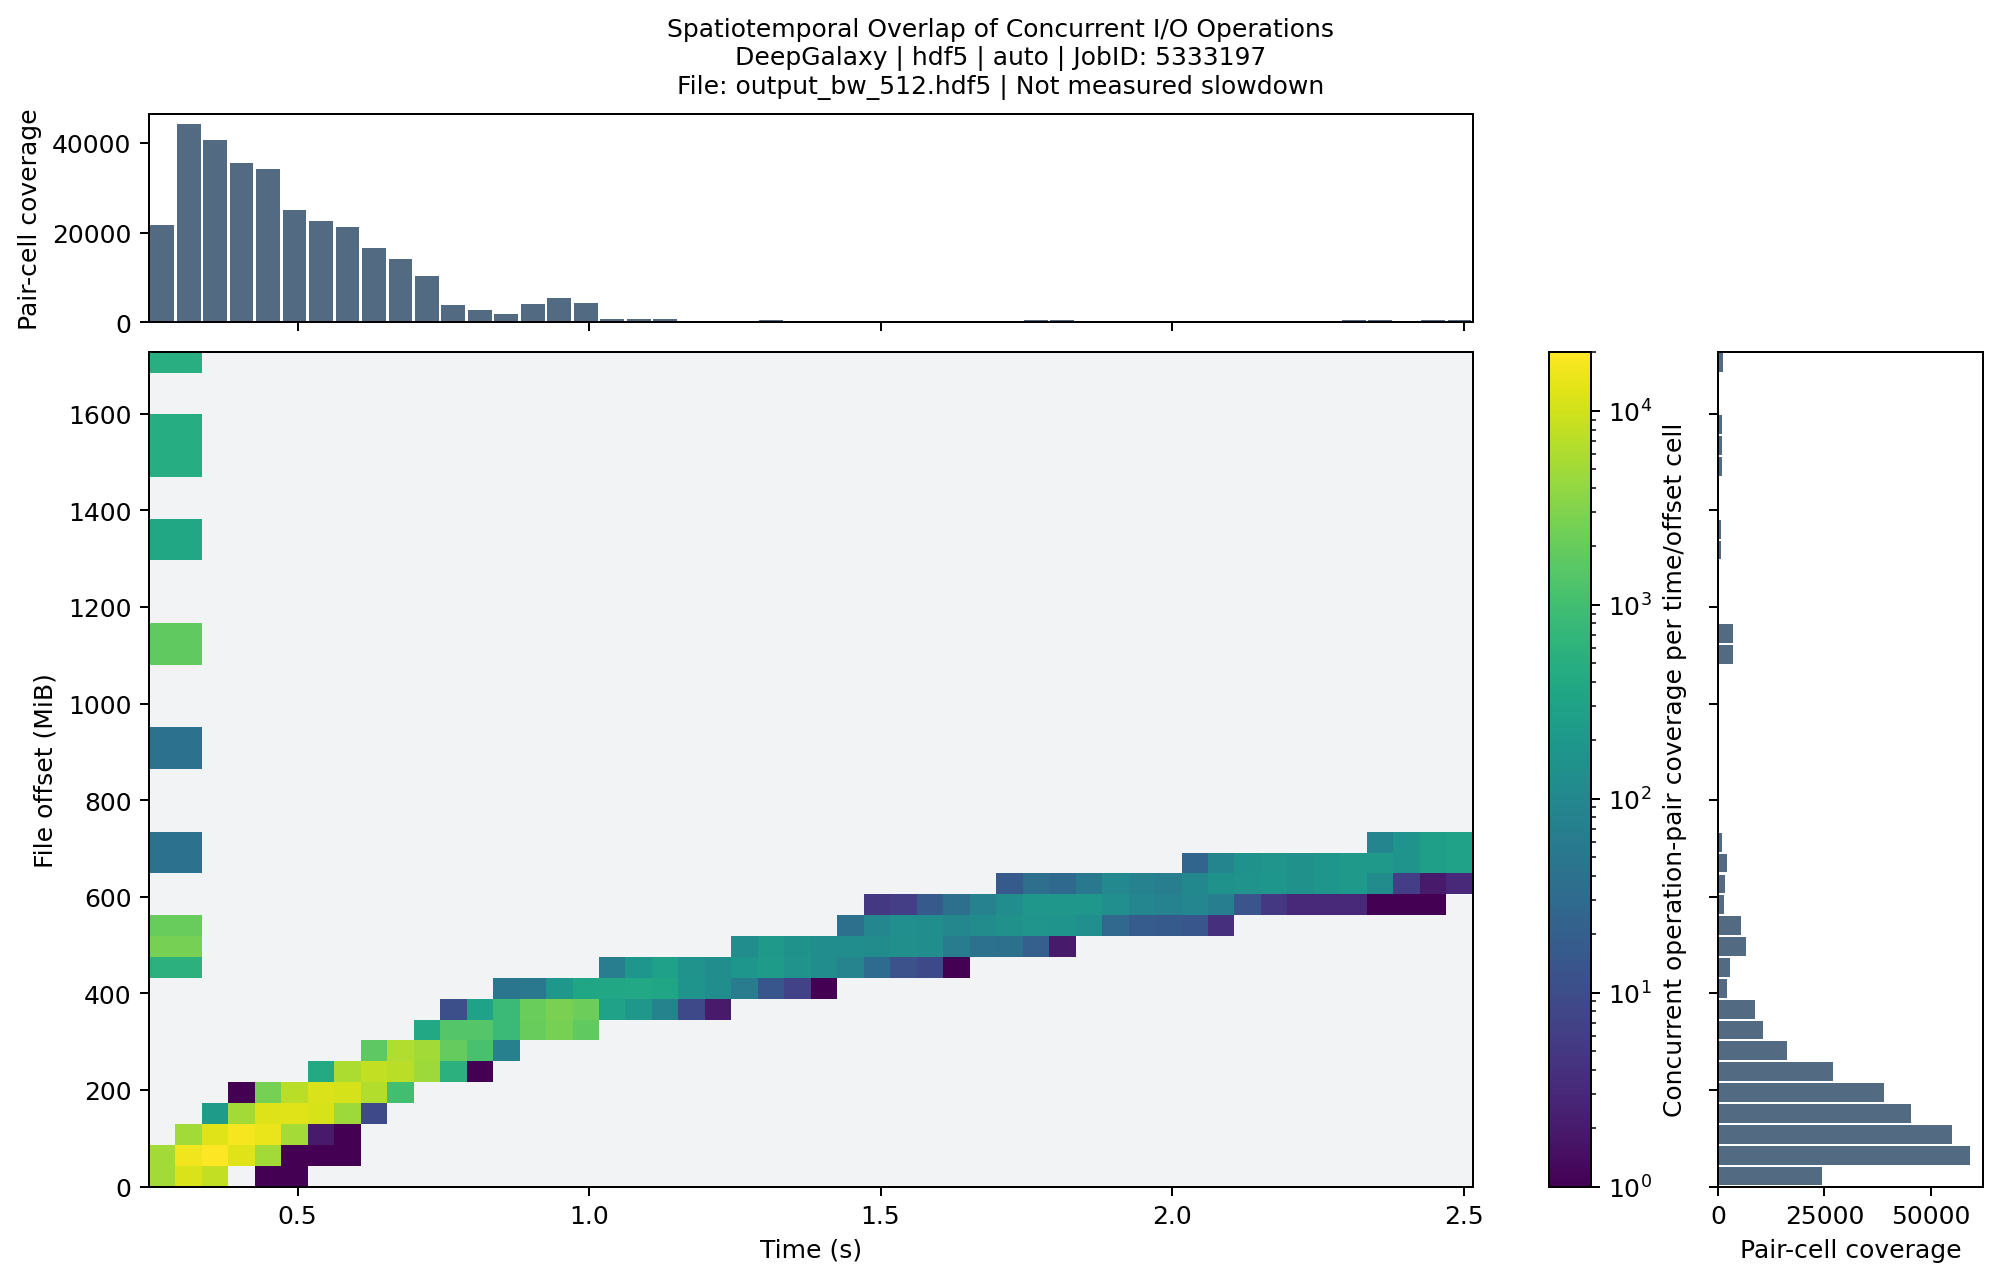

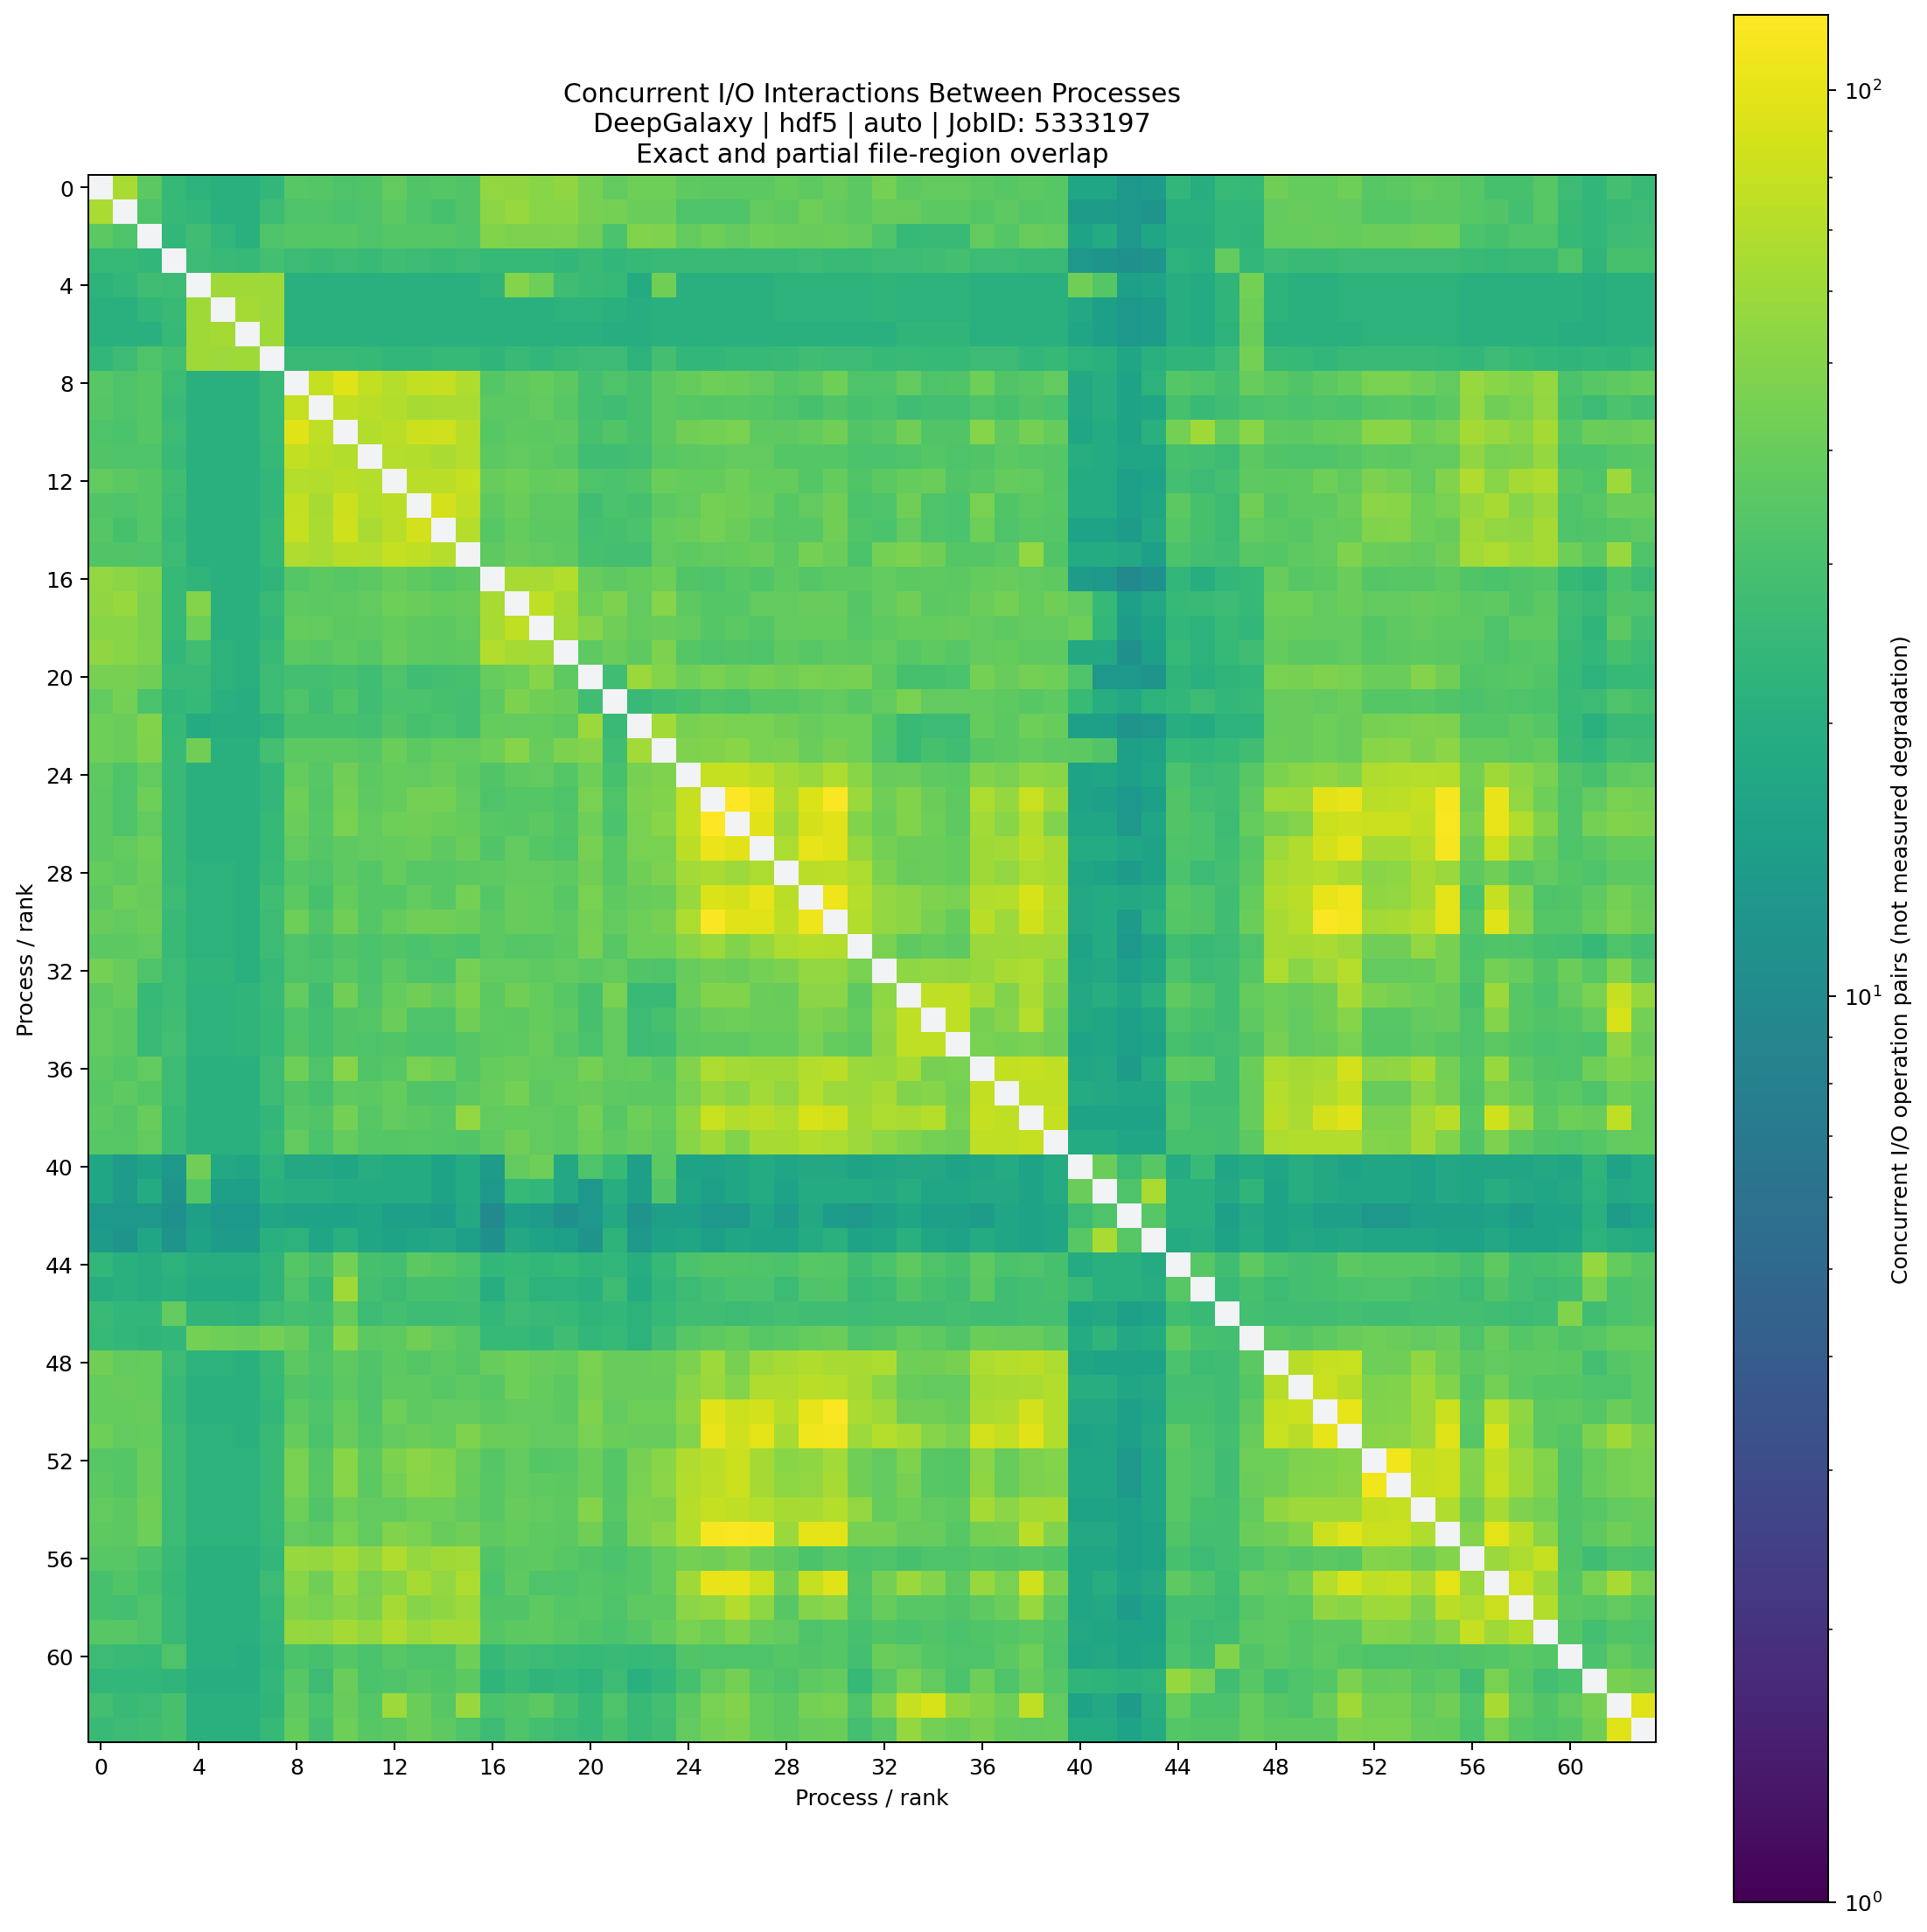

In [3]:
result = run_contention(
    campaign_root=CAMPAIGN_ROOT, application=APPLICATION,
    dataset_group=DATASET_GROUP, scenario=SCENARIO, file_format=FILE_FORMAT,
    job_id=JOBID, operation=OPERATION, case=CASE, process=PROCESS, file=FILE,
    time_bins=TIME_BINS, offset_bins=OFFSET_BINS,
    resource_mode=RESOURCE_MODE, output_dir=OUTPUT_DIR,
    palette=PALETTE, log_scale=LOG_SCALE,
)
print("Eventos DXT:", result["event_count"])
print("Pares detectados:", result["pair_count"])
print("Casos:", result["diagnostics"].get("cases"))
print("Truncado:", result["diagnostics"].get("truncated"))
print("Fuentes:", *result["source_files"], sep="\n - ")
print("Resultados:", result["output_dir"])
if not result["figures"]:
    print("Sin figuras para el filtro seleccionado: comprueba CASE, PROCESS y FILE.")
for fig in result["figures"]:
    display(Image(filename=str(fig)))
